# Osteocyte phenotypes: elongated vs rounded

**Hypothesis.** Osteocytes come in two kinds:

- *elongated*: elongated body, long dendrites that run mostly (not only) along the body's main axis;
- *rounded*: flat, pancake-like body, dendrites spreading in a star.

**Questions.**

1. Do these two groups emerge from the measured features without being imposed?
2. If so, where does each kind sit relative to the main axis of the convex hull containing all cells of its stack:
   near the axis or at the periphery?

All osteocytes are pooled into one population; `series` is kept for inspection and for permutation tests that respect
the stack each cell comes from.

Change anything in the **Settings** cell and re-run all cells. Data come from `../data/aggregate/`, refreshed by every
`scripts/import_series.py`. Body shape and orientation (`body_*` columns) exist for series exported after 14 Oct 2026;
for older exports the notebook falls back to whole-cell shape and says so.

## Settings

In [1]:
from pathlib import Path

DATA = Path("../data/aggregate")
RESULTS = Path("results")

MIN_DENDRITES = 1               # cells with fewer counted dendrites are removed
MIN_LONG_DENDRITES = 1          # ... and so are cells with fewer than this many dendrites reaching LONG_DENDRITE_UM
LONG_DENDRITE_UM = 3.0          #     (only 2-3 µm surface bumps); 0 switches the rule off. Stricter values also remove
                                #     genuine osteocytes whose processes the segmentation does not resolve
# blobs (residual compact regions): large, smooth and almost without processes. Fitted to a by-eye list of 19 blobs
# (17/19 reproduced, 4 other cells flagged; ~75% expected on unseen cells); reviewed exceptions go in BLOB_OVERRIDES
# manual tags from annotate.py decide for every cell that has them: 'junk' in BLOB_REVIEW (and 'unsure' if
# EXCLUDE_UNSURE) is excluded, everything else kept. The blob rule, its overrides and the dendrite rule below only
# apply to cells without a manual tag (e.g. a series added later)
USE_MANUAL_TAGS = True
ANNOTATIONS = Path("annotations.csv")
BLOB_REVIEW = Path("blob_review.csv")
EXCLUDE_UNSURE = False
BLOB_MAX_PROCESS_FRACTION = 0.045    # share of the cell's volume in counted dendrites
BLOB_MAX_SURFACE_PER_VOLUME = 1.26   # µm⁻¹; low for regions that are both large and smooth
BLOB_OVERRIDES = Path("blob_overrides.csv")  # series,label,decision (exclude/keep),reason
MIN_DENDRITES_FOR_DIRECTION = 3 # direction features (starriness, alignment) need this many dendrites, else NaN
DIRECTION_FROM = "base"         # dendrite direction from where it leaves the body ("base") or from the body centroid
WEIGHT_BY_REACH = False         # weight dendrite directions by reach (True) or count every dendrite equally

# features used to look for groups: column -> (axis label, log-transform before standardising).
# Body elongation only by default, so every cell can be grouped. Body flatness (3:2) is compared, not grouped on:
# the body's thin axis lies mostly along z, where confocal resolution is 2-3x worse, so thickness is inflated and
# noisy, and adding it changes the grouping a lot. A dendrite feature added here limits the grouping to cells with
# >= MIN_DENDRITES_FOR_DIRECTION dendrites
FEATURES = {
    "body_elongation":          ("Body axis ratio 2:1  (low = elongated)", False),
}
# compared between the groups afterwards, on every cell that has them; not circular when not in FEATURES
COMPARE_FEATURES = {
    "body_flatness":            ("Body axis ratio 3:2  (low = pancake)", False),
    "dendrite_starriness":      ("Dendrite starriness  (0 = one axis, 1 = star)", False),
    "dendrite_planarity":       ("Dendrite planarity  (flat star)", False),
    "dendrite_randomness":      ("Dendrite randomness  (3D star)", False),
    "dendrite_axis_alignment":  ("Dendrites along body axis, mean |cos|", False),
    "mean_dendrite_reach_um":   ("Mean dendrite reach (µm)", True),
    "n_dendrites":              ("Dendrites per cell", True),
    "body_volume_um3":          ("Body volume (µm³)", True),
}
# feature that names the groups: the group with the lower median is called "elongated"
NAMING_FEATURE = "body_elongation"

K_RANGE = range(1, 5)           # numbers of Gaussian-mixture components compared by BIC
COVARIANCE = "tied"             # mixture covariance: "tied" (one shared shape) keeps a component from fitting outliers;
                                # "full" lets each group have its own shape
MIN_GROUP_FRACTION = 0.15       # a smaller group triggers a warning: probably outliers, not a phenotype
N_BOOT = 200                    # bootstrap refits for cluster stability
N_PERM = 10000                  # within-series permutations for the location test
N_EXAMPLES = 20                 # random example cells per group
EXAMPLE_FILE = "_rotation.gif"  # file copied per example: _rotation.gif, _mip.png, _dendrites.gif or _dendrites.png
HULL_FROM_ALL_CELLS = True      # hull of every osteocyte in the stack (True) or only of the cells kept after cleaning
SEED = 20261014

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.spatial import ConvexHull, Delaunay
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

RESULTS.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)

# validated categorical slots (2 groups) and neutral inks
GROUP_COLOURS = {"elongated": "#2a78d6", "rounded": "#eb6834"}
INK = dict(primary="#0b0b0b", secondary="#52514e", muted="#898781", context="#c3c2b7", grid="#e1e0d9")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 9,
    "axes.edgecolor": INK["context"], "axes.labelcolor": INK["secondary"], "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": INK["grid"],
    "grid.linewidth": 0.6, "xtick.color": INK["muted"], "ytick.color": INK["muted"], "legend.frameon": False,
})
pd.set_option("display.width", 200)

## 1. Data and cleaning

**Manual tags first** (`USE_MANUAL_TAGS`): every cell tagged with `annotate.py` is kept or excluded by its tag:
regions reviewed as *junk* (`blob_review.csv`) are excluded, real cells (clean or dirty) kept. The rules below only
decide for cells without a tag.


Cells with no process beyond `LONG_DENDRITE_UM` (only 2–3 µm surface bumps) are removed. Stricter dendrite rules
also remove genuine osteocytes whose processes the segmentation does not resolve, such as smooth spindle-shaped
cells, so they are not used.

**Blobs** (residual compact regions, not lacunae) are removed by a rule: at most `BLOB_MAX_PROCESS_FRACTION` of the
cell's volume in processes **and** surface/volume at most `BLOB_MAX_SURFACE_PER_VOLUME` (large and smooth). The
thresholds were fitted to 19 regions judged blobs by eye. Cells where the rule and visual inspection disagree are
listed in `BLOB_OVERRIDES` (`exclude` or `keep`, with a reason); report the rule and the number of overrides.
`results/exclusion_review.png` shows every excluded cell, `results/kept_overrides.png` the cells kept against the
rule. Labels change when a series is reprocessed: the notebook reports overrides it cannot find.

In [3]:
cells_all = pd.read_csv(DATA / "osteocytes.csv")
dendrites = pd.read_csv(DATA / "dendrites.csv")

long_dendrites = (dendrites[dendrites["reach_um"] >= LONG_DENDRITE_UM].groupby(["series", "label"]).size()
                  .reindex(pd.MultiIndex.from_frame(cells_all[["series", "label"]]), fill_value=0).to_numpy())
cells_all["n_long_dendrites"] = long_dendrites
body_volume = cells_all["body_volume_um3"] if "body_volume_um3" in cells_all else cells_all["volume_um3"]
cells_all["dendrite_fraction"] = 1 - body_volume / cells_all["volume_um3"]
cells_all["surface_per_volume"] = cells_all["surface_area_um2"] / cells_all["volume_um3"]
by_rule = ((cells_all["dendrite_fraction"] <= BLOB_MAX_PROCESS_FRACTION)
           & (cells_all["surface_per_volume"] <= BLOB_MAX_SURFACE_PER_VOLUME))
overrides = (pd.read_csv(BLOB_OVERRIDES) if BLOB_OVERRIDES.exists()
             else pd.DataFrame(columns=["series", "label", "decision", "reason"]))
cell_key = pd.MultiIndex.from_frame(cells_all[["series", "label"]])
override_key = pd.MultiIndex.from_frame(overrides[["series", "label"]])
unknown = overrides[~override_key.isin(cell_key)]
if len(unknown):
    print("overrides not found in the data (series reprocessed and relabelled?):", unknown[["series", "label"]].values.tolist())
force = {d: cell_key.isin(pd.MultiIndex.from_frame(overrides.loc[overrides["decision"] == d, ["series", "label"]]))
         for d in ("exclude", "keep")}
cells_all["blob_by_rule"] = by_rule
cells_all["excluded"] = (by_rule | force["exclude"]) & ~force["keep"]
few_dendrites = (((cells_all["n_dendrites"] < MIN_DENDRITES) | (cells_all["n_long_dendrites"] < MIN_LONG_DENDRITES))
                 & ~cells_all["excluded"])

# manual tags override both rules wherever they exist
cells_all["manual"] = ""
if USE_MANUAL_TAGS and ANNOTATIONS.exists():
    ann = pd.read_csv(ANNOTATIONS)[["series", "label", "tag"]]
    rev = (pd.read_csv(BLOB_REVIEW)[["series", "label", "tag"]].rename(columns={"tag": "review"})
           if BLOB_REVIEW.exists() else pd.DataFrame(columns=["series", "label", "review"]))
    m = cells_all[["series", "label"]].merge(ann, on=["series", "label"], how="left").merge(rev, on=["series", "label"], how="left")
    manual = m["review"].fillna(m["tag"]).fillna("").to_numpy()
    cells_all["manual"] = manual
    tagged = manual != ""
    junk = (manual == "junk") | (manual == "blob/outlier") | (EXCLUDE_UNSURE & (manual == "unsure"))
    cells_all.loc[tagged, "excluded"] = junk[tagged]
    few_dendrites &= ~tagged
    print(f"manual tags for {tagged.sum()} of {len(cells_all)} cells: {junk.sum()} excluded as junk"
          + (f"; {(manual == 'blob/outlier').sum()} blob/outlier cells have no blob review and count as junk"
             if (manual == "blob/outlier").any() else ""))
keep = ~cells_all["excluded"] & ~few_dendrites
cells = cells_all[keep].copy()
by_series = cells_all.groupby("series")
cleaning = pd.DataFrame({"cells": by_series.size(),
                         "manual: junk": by_series["manual"].apply(lambda t: (t == "junk").sum()),
                         "untagged": by_series["manual"].apply(lambda t: (t == "").sum()),
                         "blobs (rule, untagged only)": by_series.apply(lambda g: (g["blob_by_rule"] & (g["manual"] == "")).sum()),
                         "overrides exclude / keep": by_series.apply(
                             lambda g: f"{force['exclude'][g.index].sum()} / {force['keep'][g.index].sum()}"),
                         "no process >= " + f"{LONG_DENDRITE_UM:g} µm": by_series.apply(lambda g: few_dendrites[g.index].sum()),
                         "kept": cells.groupby("series").size()}).fillna(0)
print(f"kept {len(cells)} of {len(cells_all)} osteocytes: {cells_all['excluded'].sum()} excluded "
      f"({(cells_all['manual'] == 'junk').sum()} manual junk), {few_dendrites.sum()} untagged with no process "
      f"reaching {LONG_DENDRITE_UM:g} µm")
cleaning

manual tags for 203 of 203 cells: 31 excluded as junk
kept 172 of 203 osteocytes: 31 excluded (31 manual junk), 0 untagged with no process reaching 3 µm


,cells,manual: junk,untagged,"blobs (rule, untagged only)",overrides exclude / keep,no process >= 3 µm,kept
series,,,,,,,
sample 1.1,51,15,0,0,1 / 2,0,36
sample 1.3,17,3,0,0,0 / 0,0,14
sample 1.4,40,3,0,0,0 / 0,0,37
sample 2.1_ultrasonic cleaned,21,1,0,0,0 / 1,0,20
sample 3.1,23,3,0,0,0 / 0,0,20
sample 3.2,27,4,0,0,0 / 0,0,23
sample 4.1,9,2,0,0,0 / 0,0,7
smple 1.2,15,0,0,0,0 / 1,0,15


In [4]:
# review sheets: every excluded blob, and the cells kept against the rule
from PIL import Image

tag = lambda s: s.replace(" ", "_").replace(".", "_")


def contact_sheet(rows, path, caption, ncols=6):
    if not len(rows):
        return
    nrows = int(np.ceil(len(rows) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.8 * ncols, 3.1 * nrows), squeeze=False)
    for ax, (_, r) in zip(axes.flat, rows.iterrows()):
        f = DATA.parent / tag(r["series"]) / "cells" / f"osteocyte_{r['label']}_mip.png"
        if f.exists():
            ax.imshow(Image.open(f))
        ax.set_title(f"{r['series'].replace('_ultrasonic cleaned', '')} #{r['label']}\n{caption(r)}", fontsize=7.5)
        ax.set_axis_off()
    for ax in axes.flat[len(rows):]:
        ax.set_visible(False)
    fig.tight_layout()
    fig.savefig(RESULTS / path)
    plt.close(fig)


reasons = overrides.set_index(["series", "label"])["reason"].to_dict()
caption = lambda r: (reasons.get((r["series"], r["label"]), "rule")[:38] + "\n"
                     f"processes {r['dendrite_fraction']:.1%}, S/V {r['surface_per_volume']:.2f}")
contact_sheet(cells_all[cells_all["excluded"]], "exclusion_review.png", caption)
contact_sheet(cells_all[force["keep"]], "kept_overrides.png", caption)
print(f"review sheets: {cells_all['excluded'].sum()} excluded, {force['keep'].sum()} kept against the rule")


review sheets: 31 excluded, 4 kept against the rule


## 2. Features

- **Body shape**: axes $a_1 \ge a_2 \ge a_3$ of the body (cell without its counted dendrites);
  elongation $a_2/a_1$ (low = elongated), flatness $a_3/a_2$ (low = pancake). Falls back to the whole cell where
  body columns are missing.
- **Dendrite directions**: unit vectors $\hat u_k$ from where each dendrite leaves the body (its base) to its tip
  (`DIRECTION_FROM`; the body centroid is the fallback for exports without base points, and makes processes leaving
  the ends of an oval body point "along the axis" by construction). Each dendrite counts equally unless
  `WEIGHT_BY_REACH`. Their orientation tensor $T = \sum_k w_k \hat u_k \hat u_k^\top / \sum_k w_k$ is axial: $\hat u$ and
  $-\hat u$ count the same, so processes at both ends of a cell are as "one-axis" as processes at one end. Its
  eigenvalues $t_1 \ge t_2 \ge t_3$ (sum 1) split into **linearity** $t_1 - t_2$ (one axis), **planarity**
  $2(t_2 - t_3)$ (flat star) and **randomness** $3t_3$ (3D star), which sum to 1 (Vollmer, *GSA Bull.* 102:786, 1990,
  [doi:10.1130/0016-7606(1990)102<0786:AAOEMT>2.3.CO;2](https://doi.org/10.1130/0016-7606(1990)102%3C0786:AAOEMT%3E2.3.CO;2)).
  **Starriness** $= 1 -$ linearity $=$ planarity $+$ randomness: 0 for bipolar or one-sided cells, 1 for any star.
  **Polarity** $(3t_1 - 1)/2$ is kept in the output for comparison.
- **Alignment with the body axis**: mean $|\hat u_k \cdot \hat a|$, $\hat a$ the body's main axis. Reference values:
  0.5 for directions random in 3D, $2/\pi \approx 0.64$ for directions random in a plane containing the axis, 1 for all
  along the axis. Needs the body axis vector, so it is only available for new exports.

In [5]:
has_body = cells["body_axis_1_um"].notna() if "body_axis_1_um" in cells else pd.Series(False, index=cells.index)
if not has_body.all():
    print("whole-cell shape used for series without body columns (re-export them):",
          sorted(cells.loc[~has_body, "series"].unique()))

def col(name, fallback):
    return cells[name].where(has_body, cells[fallback]) if name in cells else cells[fallback]

a1, a2, a3 = (col(f"body_axis_{k}_um", f"axis_{k}_um") for k in (1, 2, 3))
cells["body_elongation"] = a2 / a1
cells["body_flatness"] = a3 / a2
if "body_volume_um3" not in cells:
    cells["body_volume_um3"] = np.nan
cells["body_volume_um3"] = cells["body_volume_um3"].where(has_body, cells["volume_um3"])
centre = np.stack([col(f"body_centroid_{a}_um", f"centroid_{a}_um") for a in "zyx"], axis=1)
axis = (np.stack([cells[f"body_axis_{a}"] for a in "zyx"], axis=1) if "body_axis_z" in cells
        else np.full((len(cells), 3), np.nan))

# direction features per cell from its dendrites
tip_cols = ["tip_z_um", "tip_y_um", "tip_x_um"]
base_cols = ["base_z_um", "base_y_um", "base_x_um"]
has_base = all(c in dendrites for c in base_cols)
if DIRECTION_FROM == "base" and not has_base:
    print("no dendrite base points in these data (exports before 14 Oct 2026): directions from the body centroid")
index = {key: k for k, key in enumerate(zip(cells["series"], cells["label"]))}
direction = {name: np.full(len(cells), np.nan)
             for name in ["polarity", "linearity", "planarity", "randomness", "starriness", "axis_alignment"]}
from_centroid = set()
for key, d in dendrites.groupby(["series", "label"]):
    k = index.get(key)
    if k is None or len(d) < MIN_DENDRITES_FOR_DIRECTION:
        continue
    tips = d[tip_cols].to_numpy()
    if DIRECTION_FROM == "base" and has_base and d[base_cols].notna().all().all():
        u = tips - d[base_cols].to_numpy()
    else:
        u = tips - centre[k]
        from_centroid.add(key[0])
    u /= np.linalg.norm(u, axis=1, keepdims=True)
    w = d["reach_um"].to_numpy() if WEIGHT_BY_REACH else np.ones(len(d))
    T = (w[:, None, None] * u[:, :, None] * u[:, None, :]).sum(0) / w.sum()
    t3, t2, t1 = np.linalg.eigvalsh(T)
    direction["polarity"][k] = (3 * t1 - 1) / 2
    direction["linearity"][k] = t1 - t2
    direction["planarity"][k] = 2 * (t2 - t3)
    direction["randomness"][k] = 3 * t3
    direction["starriness"][k] = 1 - (t1 - t2)
    if np.isfinite(axis[k]).all():
        direction["axis_alignment"][k] = np.average(np.abs(u @ axis[k]), weights=w)
for name, values in direction.items():
    cells[f"dendrite_{name}"] = values
if DIRECTION_FROM == "base" and has_base and from_centroid:
    print("directions from the body centroid for series without base points (re-export them):", sorted(from_centroid))

features = {c: v for c, v in FEATURES.items() if cells[c].notna().any()}
dropped = sorted(set(FEATURES) - set(features))
if dropped:
    print("features not available in these data, left out:", dropped)
X = cells[list(features)].copy()
for c, (_, log) in features.items():
    if log:
        X[c] = np.log10(X[c])
complete = X.notna().all(axis=1)
print(f"{complete.sum()} of {len(cells)} cells have every feature "
      f"({(~complete).sum()} lack direction features: < {MIN_DENDRITES_FOR_DIRECTION} dendrites)")
cells[list(features)].describe().T.round(3)

172 of 172 cells have every feature (0 lack direction features: < 3 dendrites)


,count,mean,std,min,25%,50%,75%,max
body_elongation,172.0,0.432,0.159,0.161,0.308,0.402,0.527,0.947


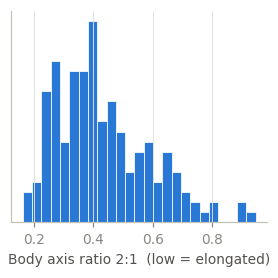

In [6]:
n = len(features)
fig, axes = plt.subplots(1, n, figsize=(2.6 * n, 2.6))
for ax, (c, (label, log)) in zip(np.atleast_1d(axes), features.items()):
    v = cells[c].dropna()
    ax.hist(v, bins=np.geomspace(v[v > 0].min(), v.max(), 25) if log else 25, color=GROUP_COLOURS["elongated"],
            edgecolor="white", linewidth=0.5)
    ax.set(xscale="log" if log else "linear", xlabel=label, yticks=[])
fig.tight_layout()

## 3. Do two groups emerge?

Features are log-transformed where flagged and standardised. Three complementary checks:

- **BIC** of Gaussian mixtures with 1–4 components: a lower BIC is better; a difference above 10 between the best
  model and the next is very strong evidence (Kass & Raftery, *JASA* 90:773, 1995,
  [doi:10.1080/01621459.1995.10476572](https://doi.org/10.1080/01621459.1995.10476572)). If one component wins, the
  data look like a single continuum.
- **Silhouette** of the two-group split: above 0.5 reasonable structure, 0.25–0.5 weak, below 0.25 none
  (Kaufman & Rousseeuw, *Finding Groups in Data*, Wiley 1990).
- **Stability**: the split is refitted on bootstrap resamples and compared with the full-data split by the adjusted
  Rand index (1 = identical, 0 = chance).

In [7]:
Z = StandardScaler().fit_transform(X[complete])
models = {k: GaussianMixture(k, covariance_type=COVARIANCE, n_init=10, random_state=SEED).fit(Z) for k in K_RANGE}
bic = pd.Series({k: m.bic(Z) for k, m in models.items()}, name="BIC")
best_k = int(bic.idxmin())
print(bic.round(1).to_string())
print(f"best by BIC: k = {best_k}; BIC(k=1) - BIC(k=2) = {bic[1] - bic[2]:.1f}")

gmm = models[2]
labels = gmm.predict(Z)
sil = silhouette_score(Z, labels)
ari = []
for _ in range(N_BOOT):
    idx = rng.integers(0, len(Z), len(Z))
    refit = GaussianMixture(2, covariance_type=COVARIANCE, n_init=3, random_state=int(rng.integers(1 << 31))).fit(Z[idx])
    ari.append(adjusted_rand_score(labels, refit.predict(Z)))
ari = np.array(ari)
print(f"two-group split: silhouette {sil:.2f}; bootstrap ARI median {np.median(ari):.2f} "
      f"[{np.percentile(ari, 5):.2f}, {np.percentile(ari, 95):.2f}] (5th–95th percentile)")

# name the groups by the naming feature
group = pd.Series(labels, index=X.index[complete])
low = cells.loc[group.index, NAMING_FEATURE].groupby(group).median().idxmin()
cells["group"] = group.map({low: "elongated", 1 - low: "rounded"})
cells["group_probability"] = pd.Series(gmm.predict_proba(Z).max(axis=1), index=group.index)
sizes = cells["group"].value_counts()
medians = cells.groupby("group")[NAMING_FEATURE].median()
if sizes.min() / sizes.sum() < MIN_GROUP_FRACTION:
    print(f"WARNING: the smaller group holds {sizes.min()} of {sizes.sum()} cells: probably outliers split off, "
          "not a phenotype; its name comes only from its median " + NAMING_FEATURE)
if abs(medians.diff().iloc[-1]) < 0.05:
    print(f"WARNING: {NAMING_FEATURE} medians differ by only {abs(medians.diff().iloc[-1]):.3f}: the names "
          "'elongated' and 'rounded' say little about these groups")
sizes

1    498.4
2    487.9
3    500.1
4    499.5
best by BIC: k = 2; BIC(k=1) - BIC(k=2) = 10.5
two-group split: silhouette 0.61; bootstrap ARI median 0.90 [0.67, 0.97] (5th–95th percentile)


group
elongated    134
rounded       38
Name: count, dtype: int64

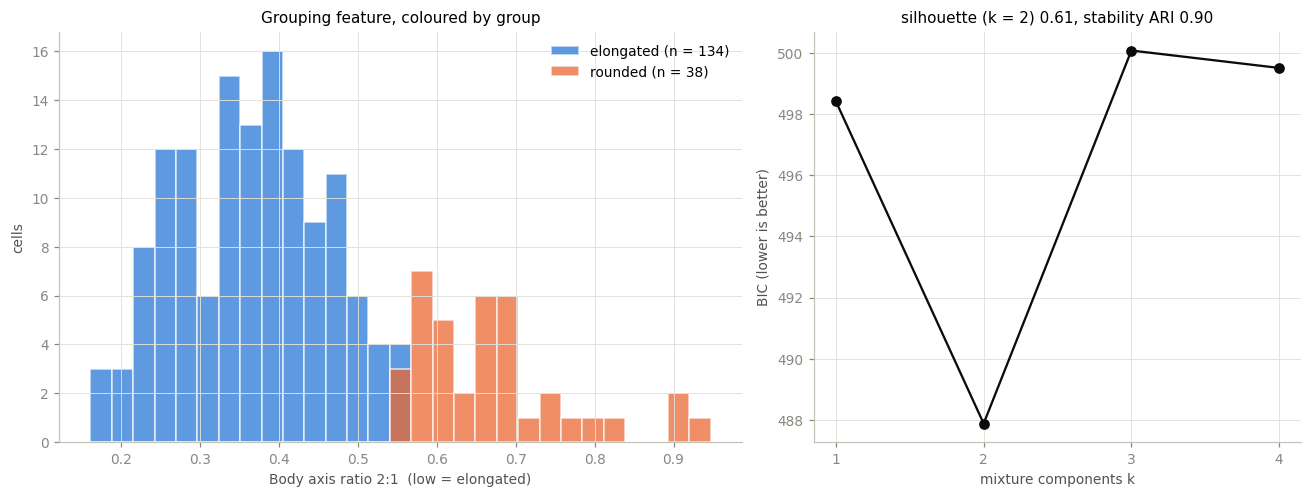

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw=dict(width_ratios=[1.4, 1]))
ax = axes[0]
if Z.shape[1] >= 2:
    pca = PCA().fit(Z)
    pcs = pca.transform(Z)
    for name, colour in GROUP_COLOURS.items():
        m = (cells.loc[group.index, "group"] == name).to_numpy()
        ax.scatter(pcs[m, 0], pcs[m, 1], s=28, color=colour, edgecolor="white", linewidth=0.8, label=f"{name} (n = {m.sum()})")
    scale = np.abs(pcs[:, :2]).max() * 0.8
    for c, (lx, ly) in zip(features, pca.components_[:2].T):
        ax.annotate("", (lx * scale, ly * scale), (0, 0), arrowprops=dict(arrowstyle="->", color=INK["muted"], lw=1))
        ax.text(lx * scale * 1.1, ly * scale * 1.1, c, fontsize=7, color=INK["secondary"], ha="center")
    ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})",
           title="Cells in feature space (arrows: feature loadings)")
    ax.legend(loc="best")
else:  # one grouping feature: its distribution, coloured by group
    only = list(features)[0]
    bins = np.linspace(cells[only].min(), cells[only].max(), 30)
    for name, colour in GROUP_COLOURS.items():
        v = cells.loc[cells["group"] == name, only].dropna()
        ax.hist(v, bins=bins, color=colour, alpha=0.75, edgecolor="white", label=f"{name} (n = {len(v)})")
    ax.set(xlabel=features[only][0], ylabel="cells", title="Grouping feature, coloured by group")
    ax.legend(loc="best")
axes[1].plot(list(bic.index), bic.values, "o-", color=INK["primary"])
axes[1].set(xlabel="mixture components k", ylabel="BIC (lower is better)", xticks=list(bic.index),
            title=f"silhouette (k = 2) {sil:.2f}, stability ARI {np.median(ari):.2f}")
fig.tight_layout()
fig.savefig(RESULTS / "phenotype_groups.png")

### Group profiles

Median [interquartile range] of every feature per group. The groups were *built* from these features, so testing
whether they differ on them is circular; read this table as a description of what separates them.

In [9]:
rows = []
for c, (label, _) in FEATURES.items():
    if c not in cells or cells[c].isna().all():
        continue
    row = {"feature": label}
    for name in GROUP_COLOURS:
        v = cells.loc[cells["group"] == name, c].dropna()
        row[name] = f"{v.median():.3g} [{v.quantile(.25):.3g}, {v.quantile(.75):.3g}]"
    rows.append(row)
profile = pd.DataFrame(rows).set_index("feature")
profile.to_csv(RESULTS / "phenotype_profiles.csv")
profile

,elongated,rounded
feature,,
Body axis ratio 2:1 (low = elongated),"0.367 [0.284, 0.432]","0.653 [0.595, 0.702]"



### Do the groups differ in their dendrites?

Each feature in `COMPARE_FEATURES` that was not used for grouping is compared between the groups on every cell that
has it (dendrite direction features need ≥ `MIN_DENDRITES_FOR_DIRECTION` dendrites). The p-value comes from shuffling
the group labels within each stack, as in the location test. With body-shape grouping this asks the hypothesis
directly: do cells with elongated bodies have one-axis dendrites, and rounder bodies starry ones?


In [10]:

def within_series_permutation(values, is_b, series, n_perm=N_PERM):
    # difference in means (b - a) and its two-sided p-value with labels shuffled within each series
    blocks = [np.flatnonzero(series == s) for s in np.unique(series)]
    diff = lambda b: values[b].mean() - values[~b].mean()
    observed, shuffled, null = diff(is_b), is_b.copy(), np.empty(n_perm)
    for i in range(n_perm):
        for blk in blocks:
            shuffled[blk] = rng.permutation(is_b[blk])
        null[i] = diff(shuffled)
    return observed, (np.sum(np.abs(null) >= abs(observed)) + 1) / (n_perm + 1)


rows = []
for c, (label, log) in COMPARE_FEATURES.items():
    if c in features or c not in cells:
        continue
    d = cells.dropna(subset=["group", c])
    if d["group"].nunique() < 2:
        continue
    v = np.log10(d[c].to_numpy()) if log else d[c].to_numpy()
    diff, p = within_series_permutation(v, (d["group"] == "rounded").to_numpy(), d["series"].to_numpy(), n_perm=2000)
    med = d.groupby("group")[c].median()
    rows.append({"feature": label, "n": len(d), "elongated (median)": med.get("elongated"),
                 "rounded (median)": med.get("rounded"),
                 "rounded - elongated (mean)": diff, "scale": "log10" if log else "linear", "p (within-stack)": p})
comparison = pd.DataFrame(rows).set_index("feature")
comparison.to_csv(RESULTS / "phenotype_comparison.csv")
comparison.round(3)


/var/folders/k2/zvg_gcvj6dz5q4_t5p1n04240000gp/T/ipykernel_46280/434623399.py:20: RuntimeWarning: divide by zero encountered in log10
  v = np.log10(d[c].to_numpy()) if log else d[c].to_numpy()


,n,elongated (median),rounded (median),rounded - elongated (mean),scale,p (within-stack)
feature,,,,,,
Body axis ratio 3:2 (low = pancake),172,0.636,0.643,-0.030,linear,0.353
"Dendrite starriness (0 = one axis, 1 = star)",162,0.637,0.706,0.070,linear,0.134
Dendrite planarity (flat star),162,0.318,0.347,-0.008,linear,0.833
Dendrite randomness (3D star),162,0.226,0.323,0.078,linear,0.062
"Dendrites along body axis, mean |cos|",162,0.666,0.625,-0.046,linear,0.297
Mean dendrite reach (µm),171,5.112,4.158,-0.066,log10,0.116
Dendrites per cell,172,6.500,9.000,inf,log10,1.000
Body volume (µm³),172,600.051,1316.072,0.267,log10,0.001


## 4. Where do the groups sit relative to the hull axis?

Per stack, in the image plane (x, y): the convex hull of all osteocytes, built from their centroids **and dendrite
tips** so that it encloses the cells' full extent and every centroid lies strictly inside; its main axis (principal
axis of the filled hull, estimated from points sampled uniformly inside it); and for each cell its **relative radial
position** $r = d / d_\mathrm{hull}$: the distance $d$ from the axis divided by the distance from the axis to the hull
boundary on the cell's side (0 on the axis, 1 on the boundary). The analysis is 2D because the stacks are only
25–55 µm deep against ~250 µm wide: the depth is set by the imaging, and in 3D every radial direction with a small
z component would hit the top or bottom of the stack almost at once.

The test compares the mean $r$ of the two groups against permutations that shuffle the group labels **within each
stack**, so differences between stacks cannot create an effect.

In [11]:
def hull_axis_positions(points, query, n_samples=20000):
    # main axis of the filled hull, then relative radial position of each query point (works in 2D or 3D)
    hull = ConvexHull(points)
    tri = Delaunay(points[hull.vertices])
    lo, hi = points.min(0), points.max(0)
    samples = rng.uniform(lo, hi, size=(n_samples, points.shape[1]))
    samples = samples[tri.find_simplex(samples) >= 0]
    centre = samples.mean(0)
    axis = np.linalg.eigh(np.cov((samples - centre).T))[1][:, -1]
    rel = query - centre
    foot = centre + np.outer(rel @ axis, axis)
    radial = query - foot
    d = np.linalg.norm(radial, axis=1)
    u = radial / np.where(d > 0, d, 1)[:, None]
    normals, offsets = hull.equations[:, :-1], hull.equations[:, -1]
    # distance along u from the axis foot to the first facet: n·(foot + t u) + b = 0, over facets with n·u > 0
    nu = u @ normals.T
    t = -(foot @ normals.T + offsets) / np.where(nu > 1e-12, nu, np.nan)
    d_hull = np.nanmin(np.where(t > 0, t, np.nan), axis=1)
    return d / d_hull, d, rel @ axis, centre, axis, hull


centroids, tips = ["centroid_y_um", "centroid_x_um"], ["tip_y_um", "tip_x_um"]
geometry = {}
cells["radial_position"] = np.nan
cells["distance_to_axis_um"] = np.nan
for s, g in cells.groupby("series"):
    members = (cells_all if HULL_FROM_ALL_CELLS else cells).query("series == @s")
    d_tips = dendrites[(dendrites["series"] == s) & dendrites["label"].isin(members["label"])]
    pts = np.vstack([members[centroids].to_numpy(), d_tips[tips].to_numpy()])
    if len(members) < 5:
        print(f"{s}: too few cells for a hull")
        continue
    r, d, along, centre_s, axis_s, hull = hull_axis_positions(pts, g[centroids].to_numpy())
    cells.loc[g.index, "radial_position"] = r
    cells.loc[g.index, "distance_to_axis_um"] = d
    geometry[s] = (pts, centre_s, axis_s, hull)

located = cells.dropna(subset=["group", "radial_position"])
located.groupby("group")["radial_position"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
elongated,134.0,0.462,0.267,0.000,0.271,0.430,0.690,1.000
rounded,38.0,0.468,0.279,0.067,0.196,0.447,0.694,0.873


In [12]:
r = located["radial_position"].to_numpy()
is_rounded = (located["group"] == "rounded").to_numpy()
blocks = [np.flatnonzero(located["series"].to_numpy() == s) for s in located["series"].unique()]


def mean_difference(rounded):
    return r[rounded].mean() - r[~rounded].mean()


observed = mean_difference(is_rounded)
perm = np.empty(N_PERM)
shuffled = is_rounded.copy()
for i in range(N_PERM):
    for b in blocks:  # shuffle group labels within each stack only
        shuffled[b] = rng.permutation(is_rounded[b])
    perm[i] = mean_difference(shuffled)
p_perm = (np.sum(np.abs(perm) >= abs(observed)) + 1) / (N_PERM + 1)
print(f"mean radial position, rounded − elongated = {observed:+.3f} "
      f"(within-stack permutation p = {p_perm:.3g}, two-sided, {N_PERM} permutations)")

per_series = located.groupby(["series", "group"])["radial_position"].median().unstack()
per_series["n"] = located.groupby("series").size()
per_series.round(3)

mean radial position, rounded − elongated = +0.006 (within-stack permutation p = 0.907, two-sided, 10000 permutations)


group,elongated,rounded,n
series,,,
sample 1.1,0.591,0.345,36
sample 1.3,0.380,0.620,14
sample 1.4,0.319,0.673,37
sample 2.1_ultrasonic cleaned,0.439,NaN,20
sample 3.1,0.408,0.372,20
sample 3.2,0.410,0.708,23
sample 4.1,0.691,0.188,7
smple 1.2,0.626,0.117,15


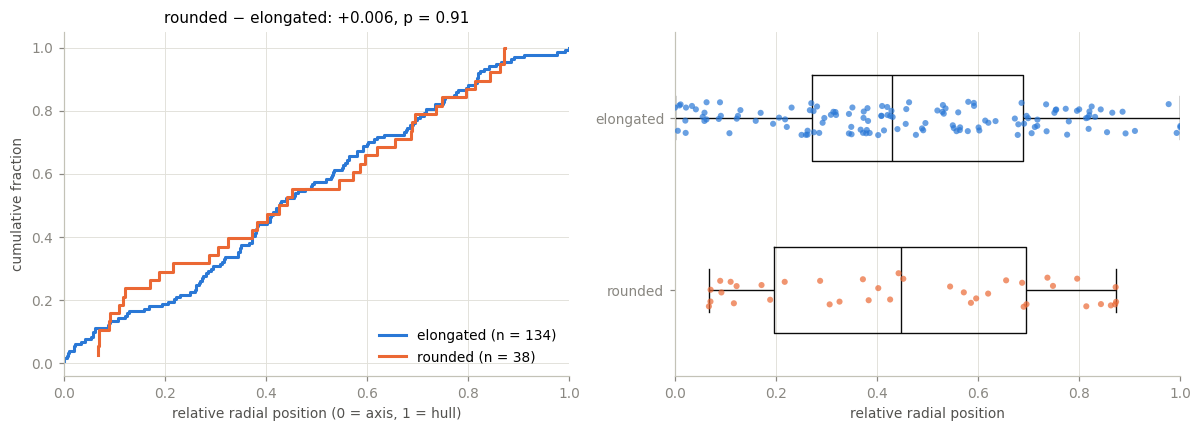

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, colour in GROUP_COLOURS.items():
    v = np.sort(located.loc[located["group"] == name, "radial_position"].to_numpy())
    axes[0].step(v, np.arange(1, len(v) + 1) / len(v), color=colour, linewidth=2, label=f"{name} (n = {len(v)})")
axes[0].set(xlabel="relative radial position (0 = axis, 1 = hull)", ylabel="cumulative fraction", xlim=(0, 1),
            title=f"rounded − elongated: {observed:+.3f}, p = {p_perm:.2g}")
axes[0].legend(loc="lower right")
sns.stripplot(located, x="radial_position", y="group", order=list(GROUP_COLOURS), hue="group",
              palette=GROUP_COLOURS, legend=False, size=4, alpha=0.7, ax=axes[1])
sns.boxplot(located, x="radial_position", y="group", order=list(GROUP_COLOURS), showfliers=False, fill=False,
            color=INK["primary"], width=0.5, linewidth=0.9, ax=axes[1])
axes[1].set(xlabel="relative radial position", ylabel="", xlim=(0, 1))
fig.tight_layout()
fig.savefig(RESULTS / "phenotype_location.png")


### Roundness against distance from the axis

Body roundness (axis ratio 2:1, high = round) for every cell against its relative radial position (left) and its
distance from the hull axis in µm (right), coloured by group. The black line is a running median (window of
`ROUNDNESS_WINDOW` cells); ρ is Spearman's rank correlation, with a p-value from shuffling roundness within each stack.
This needs no groups, so it also shows whether the round cells sit at particular distances.


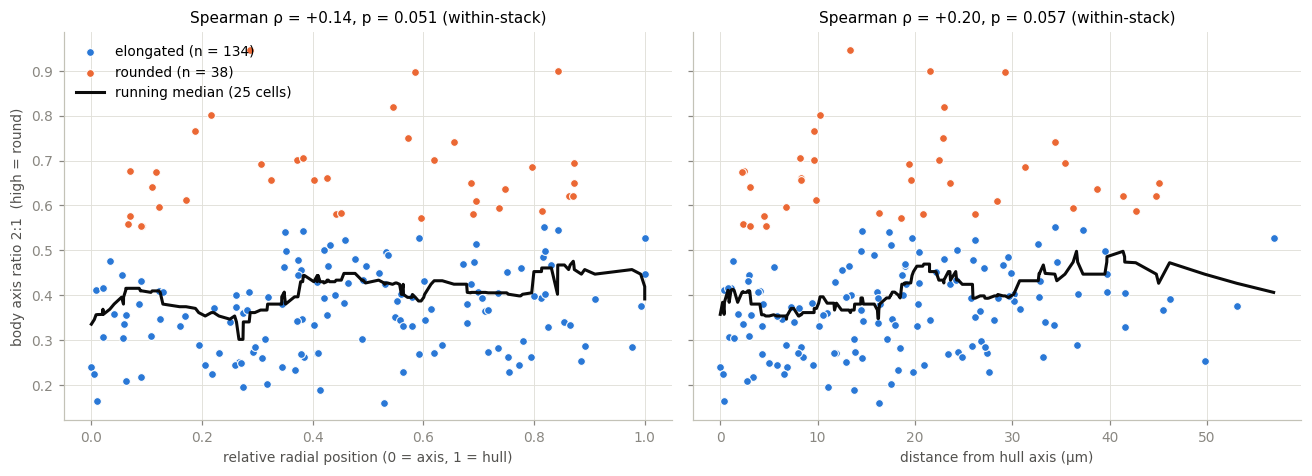

In [14]:

ROUNDNESS_WINDOW = 25


def spearman_within_series(x, y, series, n_perm=N_PERM):
    rho = stats.spearmanr(x, y).statistic
    blocks = [np.flatnonzero(series == s) for s in np.unique(series)]
    shuffled, null = y.copy(), np.empty(n_perm)
    for i in range(n_perm):
        for b in blocks:
            shuffled[b] = rng.permutation(y[b])
        null[i] = stats.spearmanr(x, shuffled).statistic
    return rho, (np.sum(np.abs(null) >= abs(rho)) + 1) / (n_perm + 1)


d = cells.dropna(subset=["radial_position", "body_elongation"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, xcol, xlabel in [(axes[0], "radial_position", "relative radial position (0 = axis, 1 = hull)"),
                         (axes[1], "distance_to_axis_um", "distance from hull axis (µm)")]:
    for name, colour in GROUP_COLOURS.items():
        g = d[d["group"] == name]
        ax.scatter(g[xcol], g["body_elongation"], s=26, color=colour, edgecolor="white", linewidth=0.7,
                   label=f"{name} (n = {len(g)})", zorder=3)
    order = d.sort_values(xcol)
    ax.plot(order[xcol], order["body_elongation"].rolling(ROUNDNESS_WINDOW, center=True, min_periods=ROUNDNESS_WINDOW // 2).median(),
            color=INK["primary"], linewidth=2, label=f"running median ({ROUNDNESS_WINDOW} cells)", zorder=4)
    rho, p = spearman_within_series(d[xcol].to_numpy(), d["body_elongation"].to_numpy(), d["series"].to_numpy())
    ax.set(xlabel=xlabel, title=f"Spearman ρ = {rho:+.2f}, p = {p:.2g} (within-stack)")
axes[0].set_ylabel("body axis ratio 2:1  (high = round)")
axes[0].legend(loc="upper left")
fig.tight_layout()
fig.savefig(RESULTS / "roundness_vs_distance.png")


Per stack, top view (x, y): hull of the cells' full extent, its main axis, and the cell centroids coloured by group (grey: not grouped).

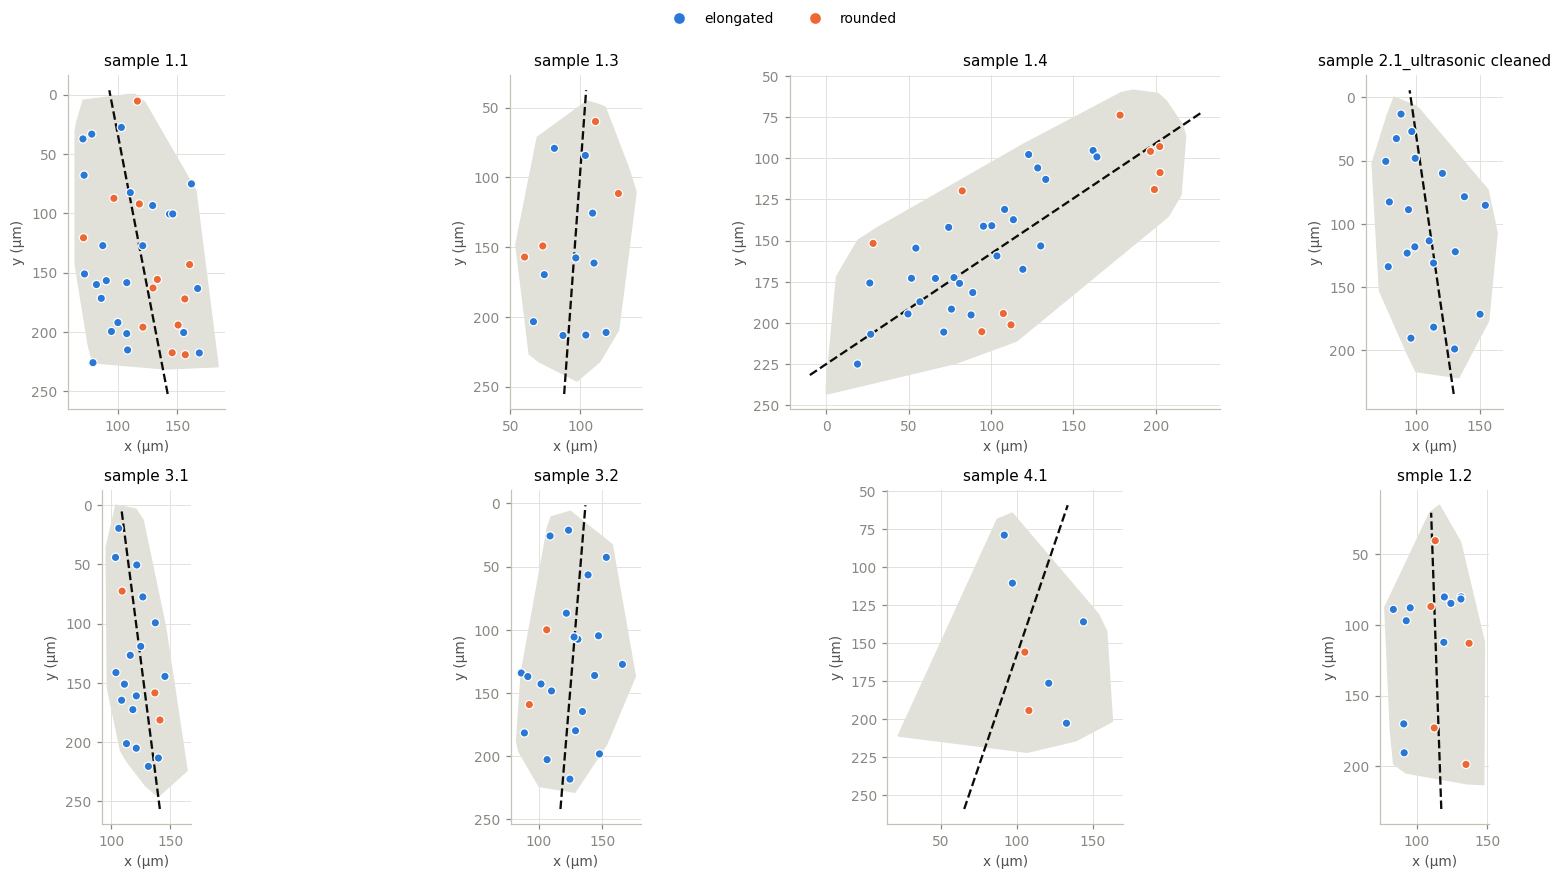

In [15]:
n = len(geometry)
ncols = 4
fig, axes = plt.subplots(int(np.ceil(n / ncols)), ncols, figsize=(4 * ncols, 4 * np.ceil(n / ncols)), squeeze=False)
for ax, (s, (pts, centre_s, axis_s, hull)) in zip(axes.flat, geometry.items()):
    ax.fill(pts[hull.vertices, 1], pts[hull.vertices, 0], color=INK["grid"], zorder=0)
    span = np.linalg.norm(pts.max(0) - pts.min(0)) / 2
    ends = centre_s + np.outer([-span, span], axis_s)
    ax.plot(ends[:, 1], ends[:, 0], color=INK["primary"], linewidth=1.5, linestyle="--")
    g = cells[cells["series"] == s]
    colour = g["group"].map(GROUP_COLOURS).fillna(INK["context"])
    ax.scatter(g["centroid_x_um"], g["centroid_y_um"], c=colour, s=30, edgecolor="white", linewidth=0.8, zorder=3)
    ax.set(title=s, aspect="equal", xlabel="x (µm)", ylabel="y (µm)")
    ax.invert_yaxis()
for ax in axes.flat[n:]:
    ax.set_visible(False)
handles = [plt.Line2D([], [], marker="o", linestyle="", color=c, label=k) for k, c in GROUP_COLOURS.items()]
fig.legend(handles=handles, loc="upper center", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(RESULTS / "phenotype_maps.png")


## Examples

`N_EXAMPLES` cells drawn at random from each group (reproducible with `SEED`). One rendering per cell
(`EXAMPLE_FILE`, the rotating ch1 projection by default) is copied from `../data/<series>/cells/` into
`results/examples/<group>/` as `<series>_<label><file>`, and a contact sheet per group shows the cells' MIPs with their
grouping features. The folder is rewritten on every run.


elongated: 20 cells -> results/examples/elongated
rounded: 20 cells -> results/examples/rounded


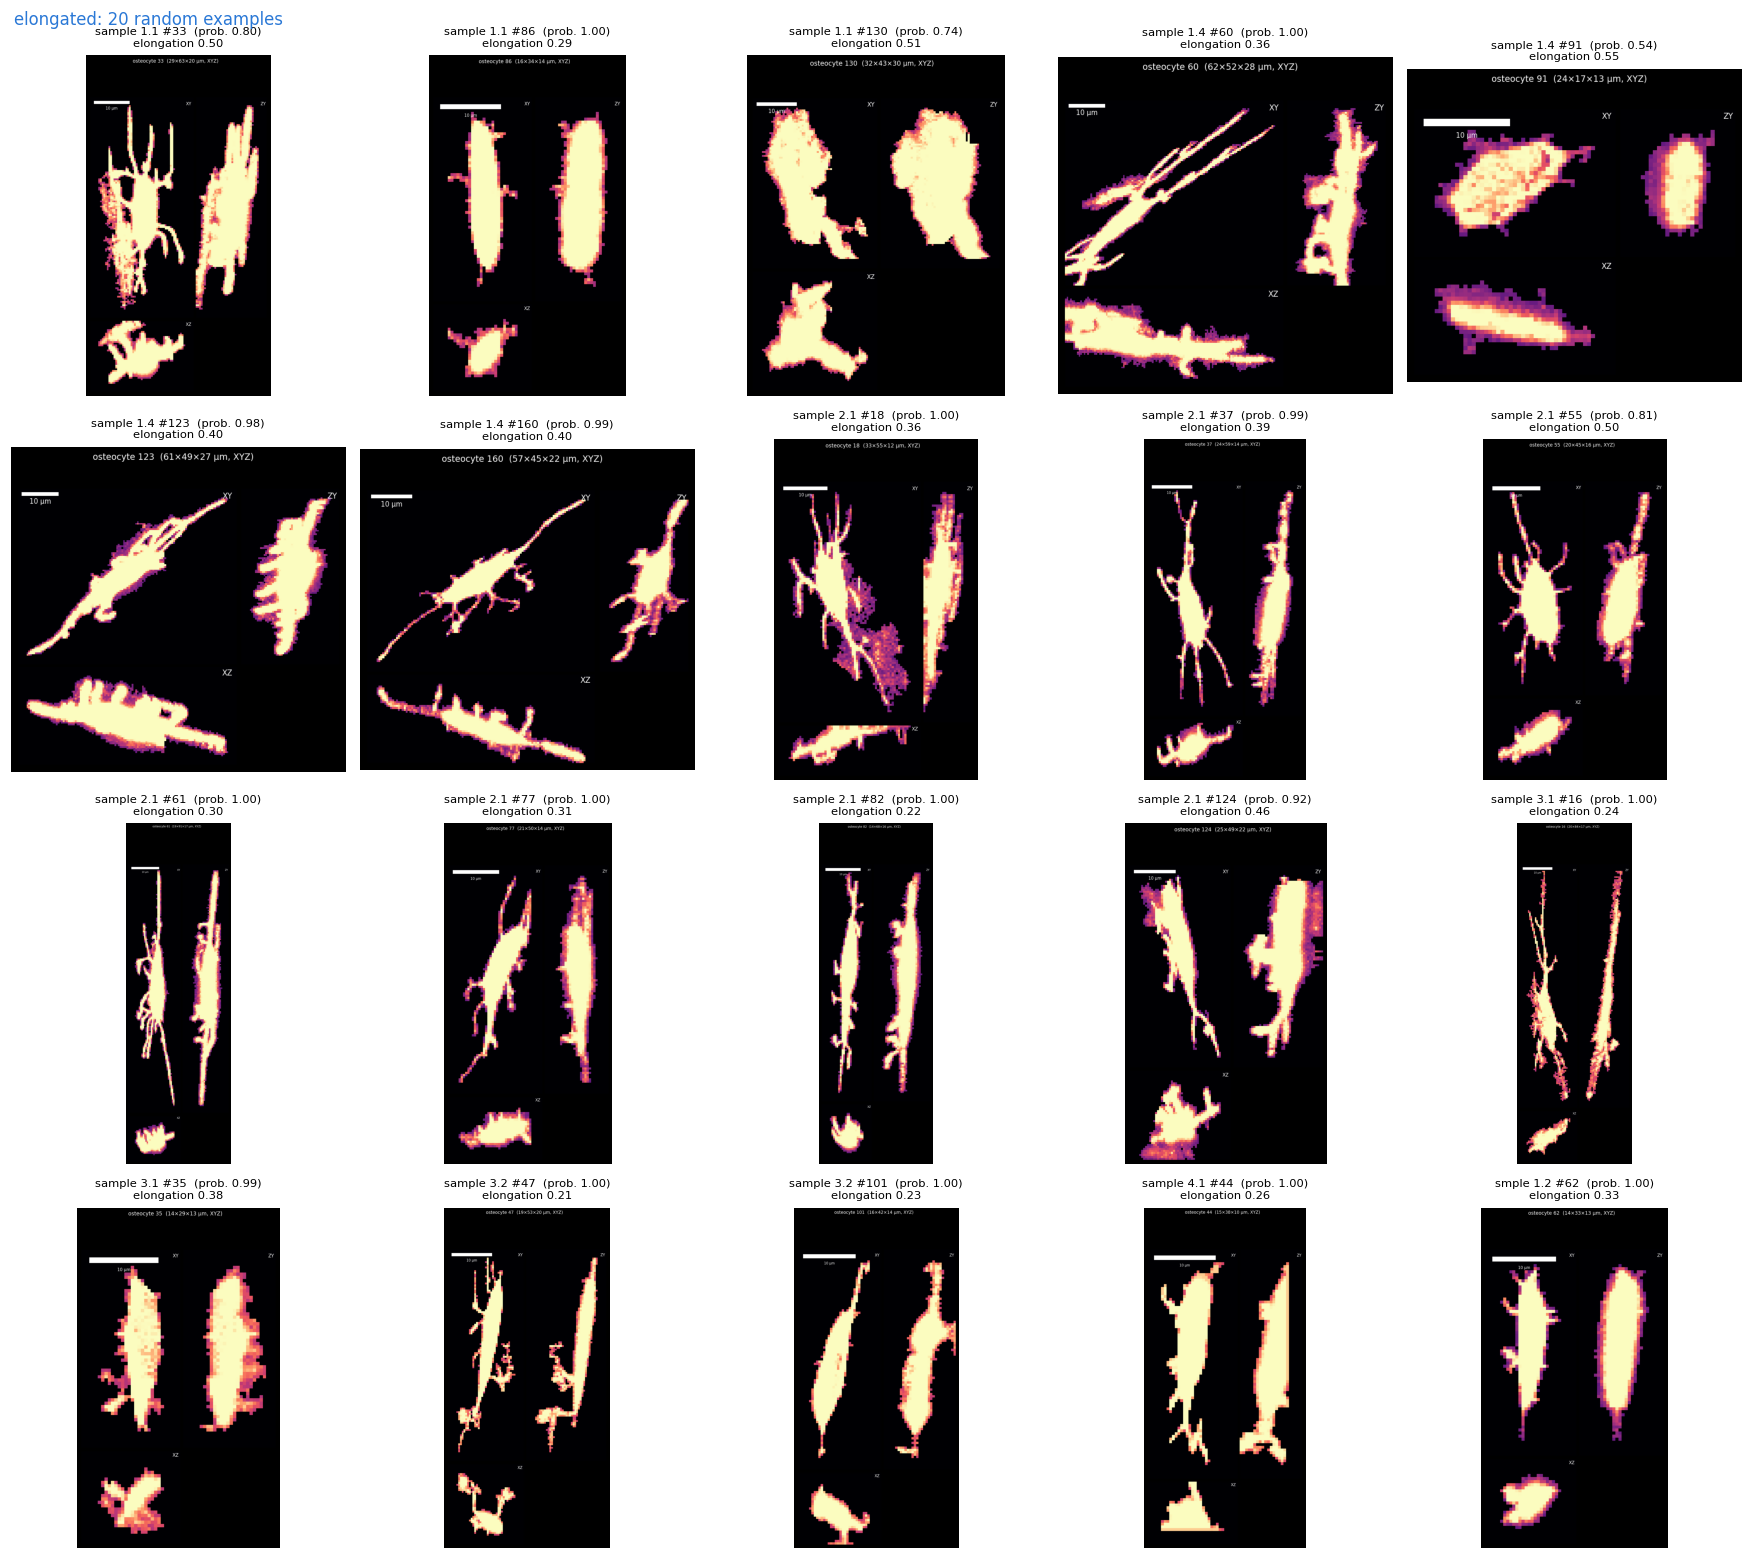

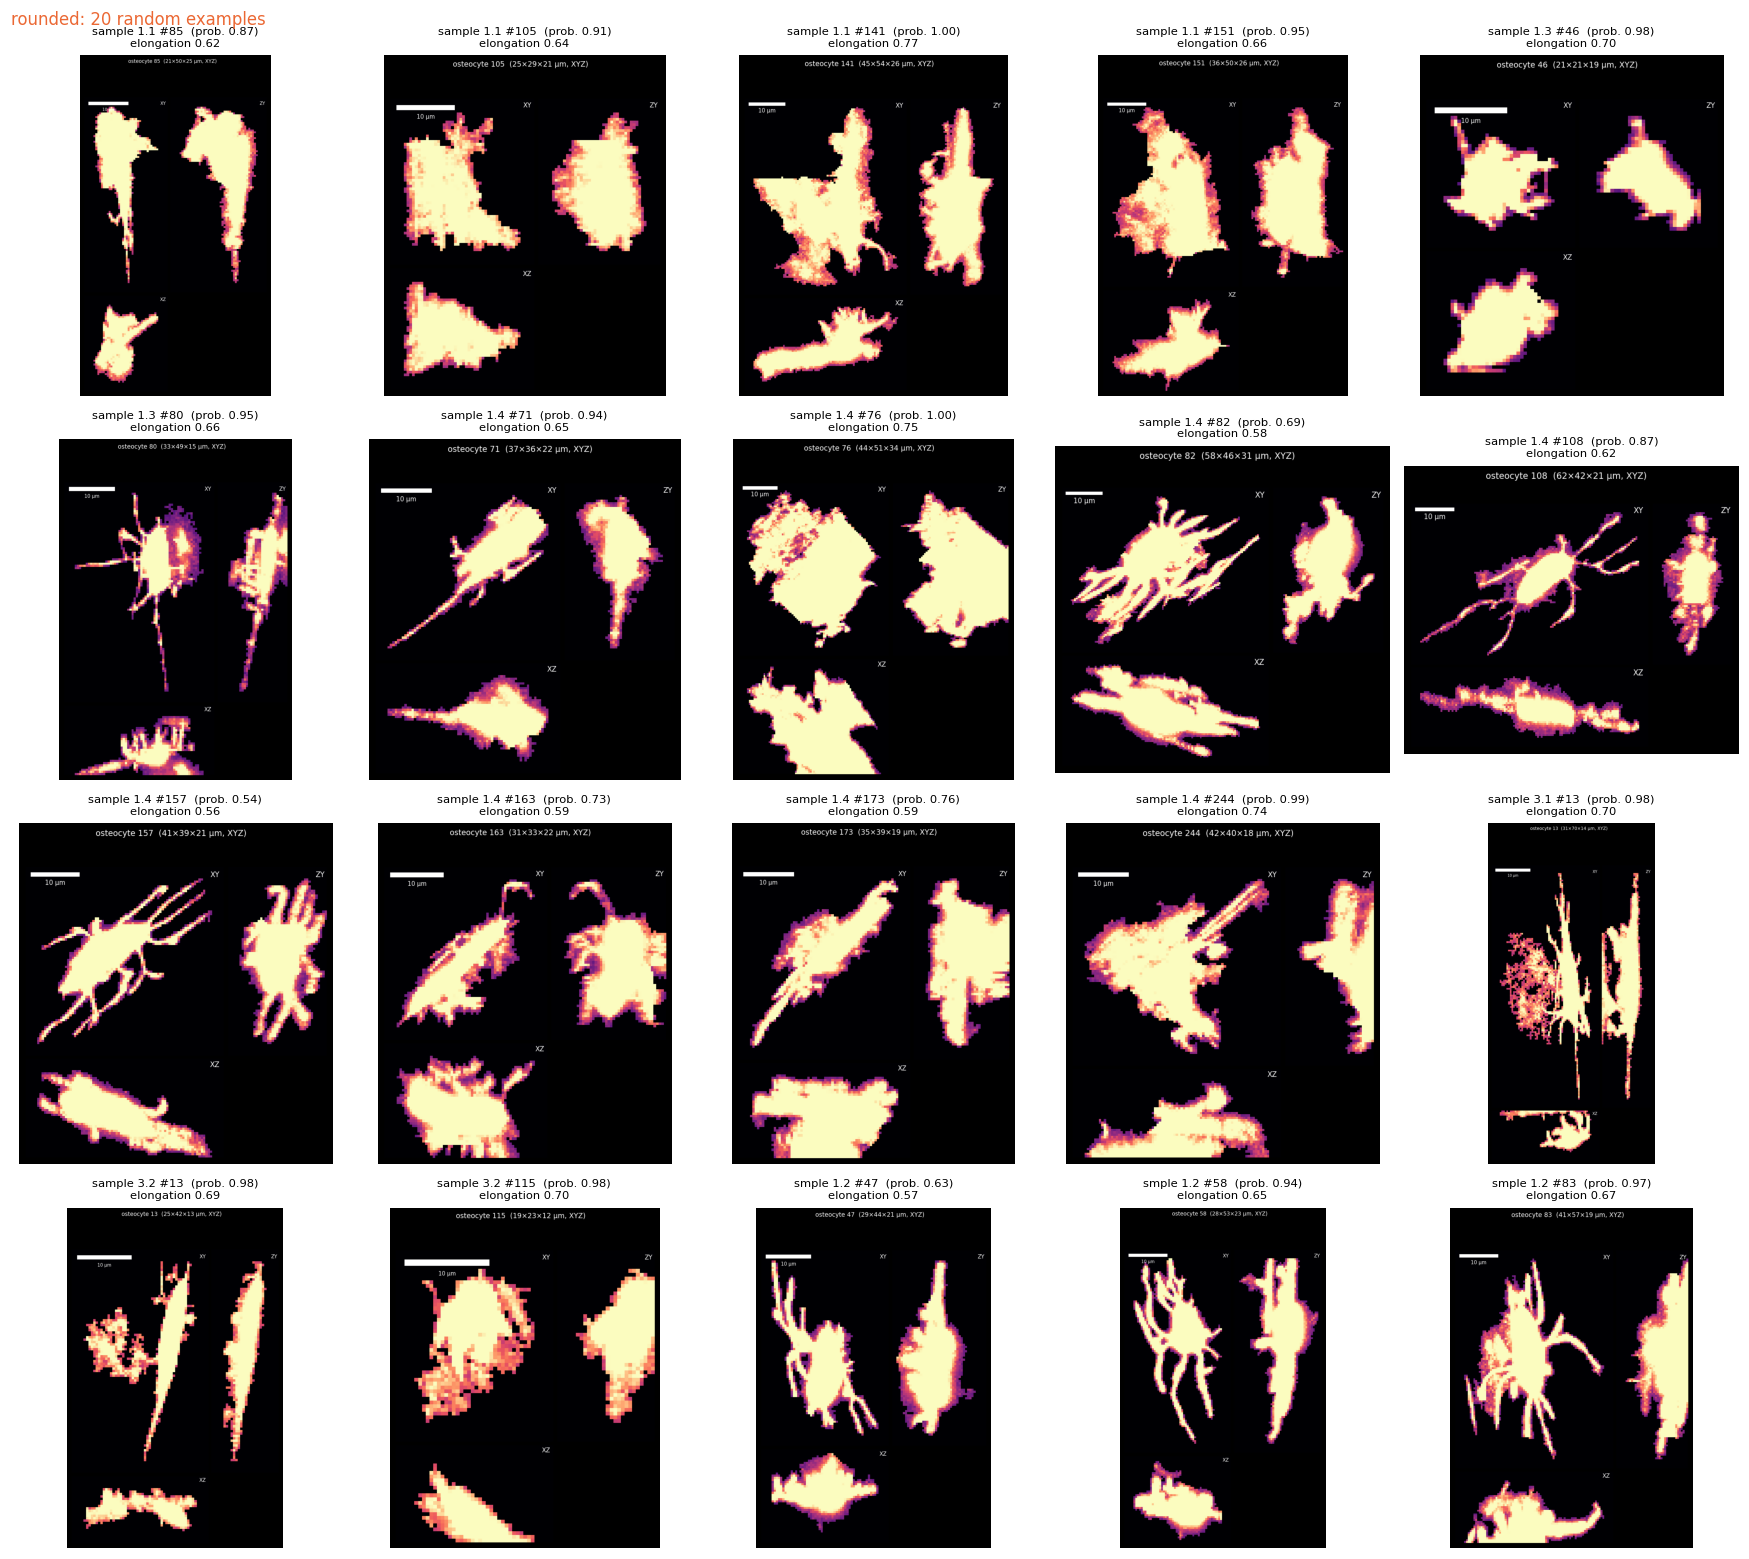

In [16]:

import shutil
from PIL import Image

EXAMPLES = RESULTS / "examples"
shutil.rmtree(EXAMPLES, ignore_errors=True)
example_rng = np.random.default_rng(SEED)
tag = lambda s: s.replace(" ", "_").replace(".", "_")

examples = {}
for name in GROUP_COLOURS:
    members = cells[cells["group"] == name]
    pick = members.iloc[np.sort(example_rng.choice(len(members), min(N_EXAMPLES, len(members)), replace=False))]
    examples[name] = pick
    out = EXAMPLES / name
    out.mkdir(parents=True)
    missing = 0
    for _, r in pick.iterrows():
        f = DATA.parent / tag(r["series"]) / "cells" / f"osteocyte_{r['label']}{EXAMPLE_FILE}"
        if f.exists():
            shutil.copy2(f, out / f"{tag(r['series'])}_{r['label']}{EXAMPLE_FILE}")
        else:
            missing += 1
    print(f"{name}: {len(pick)} cells -> {out}" + (f" ({missing} without {EXAMPLE_FILE})" if missing else ""))

ncols = 5
SHORT = {"body_elongation": "elongation", "body_flatness": "flatness", "dendrite_starriness": "starriness",
         "dendrite_axis_alignment": "alignment", "dendrite_planarity": "planarity", "dendrite_randomness": "randomness",
         "mean_dendrite_reach_um": "reach µm", "n_dendrites": "dendrites", "body_volume_um3": "volume µm³"}
short = lambda c: SHORT.get(c, c)
for name, pick in examples.items():
    if not len(pick):
        continue
    nrows = int(np.ceil(len(pick) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.6 * nrows), squeeze=False)
    for ax, (_, r) in zip(axes.flat, pick.iterrows()):
        f = DATA.parent / tag(r["series"]) / "cells" / f"osteocyte_{r['label']}_mip.png"
        if f.exists():
            ax.imshow(Image.open(f))
        parts = [f"{short(c)} {r[c]:.2f}" for c in features if np.isfinite(r[c])]
        caption = "\n".join(" · ".join(parts[k:k + 2]) for k in range(0, len(parts), 2))
        ax.set_title(f"{r['series'].replace('_ultrasonic cleaned', '')} #{r['label']}  "
                     f"(prob. {r['group_probability']:.2f})\n{caption}", fontsize=7.5)
        ax.set_axis_off()
    for ax in axes.flat[len(pick):]:
        ax.set_visible(False)
    fig.suptitle(f"{name}: {len(pick)} random examples", x=0.01, ha="left", color=GROUP_COLOURS[name])
    fig.tight_layout()
    fig.savefig(EXAMPLES / f"{name}_contact_sheet.png")


## 5. Save

In [17]:
direction_cols = [c for c in cells if c.startswith("dendrite_") and c not in features]
out = cells[["series", "label", "group", "group_probability", "radial_position", "distance_to_axis_um", *features,
             *direction_cols]]
out.to_csv(RESULTS / "phenotypes.csv", index=False)
print(f"wrote {RESULTS / 'phenotypes.csv'} ({len(out)} cells)")

wrote results/phenotypes.csv (172 cells)
